# 1. Import Libraries

In [1]:
import os
import re
import json
import time
from pathlib import Path

import joblib
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from anthropic import Anthropic
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 2. Verify required files

In [2]:
required_files = [
    "test_300.csv",
    "vader_predictions.csv",
    "vader_metrics.csv",
    "naive_bayes_predictions.csv",
    "naive_bayes_metrics.csv",
    "naive_bayes_model.pkl",
    "tfidf_vectorizer.pkl",
    "claude_predictions.csv",
    "claude_metrics.csv"
]

missing_files = [
    file
    for file in required_files
    if not Path(file).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing required files: {missing_files}"
    )

print("All required Day 1–4 files are available.")

All required Day 1–4 files are available.


# 3. Load and verify the existing metrics

### 3.1 Load the three metric files

In [3]:
vader_metrics = pd.read_csv(
    "vader_metrics.csv"
)

nb_metrics = pd.read_csv(
    "naive_bayes_metrics.csv"
)

claude_metrics = pd.read_csv(
    "claude_metrics.csv"
)

print("VADER metrics:")
display(vader_metrics)

print("Naive Bayes metrics:")
display(nb_metrics)

print("Claude metrics:")
display(claude_metrics)

VADER metrics:


,model,accuracy,macro_f1,seconds_per_1000,cost_per_1000
0,VADER,0.696667,0.688353,2.486687,0.0


Naive Bayes metrics:


,model,accuracy,macro_f1,seconds_per_1000,cost_per_1000
0,NLTK + Naive Bayes,0.84,0.839972,0.008861,0.0


Claude metrics:


,model,model_id,accuracy,macro_f1,seconds_per_1000,cost_per_1000,total_input_tokens,total_output_tokens,recorded_api_cost,valid_predictions,invalid_predictions
0,Claude Haiku 5.5 zero-shot,claude-haiku-5-5,0.92,0.919643,860.996516,0.052979,151171,1553,0.015894,300,0


### 3.2 Standardize model names

In [4]:
vader_metrics["model"] = "VADER"

nb_metrics["model"] = "TF-IDF + Naive Bayes"

claude_metrics["model"] = "Claude Haiku 5.5"

### 3.3 Combine the main metrics

In [5]:
main_metrics = pd.concat(
    [
        vader_metrics[
            [
                "model",
                "accuracy",
                "macro_f1",
                "seconds_per_1000",
                "cost_per_1000"
            ]
        ],
        nb_metrics[
            [
                "model",
                "accuracy",
                "macro_f1",
                "seconds_per_1000",
                "cost_per_1000"
            ]
        ],
        claude_metrics[
            [
                "model",
                "accuracy",
                "macro_f1",
                "seconds_per_1000",
                "cost_per_1000"
            ]
        ]
    ],
    ignore_index=True
)

main_metrics

,model,accuracy,macro_f1,seconds_per_1000,cost_per_1000
0,VADER,0.696667,0.688353,2.486687,0.000000
1,TF-IDF + Naive Bayes,0.840000,0.839972,0.008861,0.000000
2,Claude Haiku 5.5,0.920000,0.919643,860.996516,0.052979


# 4. Create the required 30 hard cases

### 4.1 Create the 30 hard-case sentences

In [6]:
hard_cases_data = [
    {
        "text": "I expected to hate this movie, but I absolutely loved it.",
        "label": "positive",
        "category": "contrast"
    },
    {
        "text": "The movie was not bad at all and was surprisingly enjoyable.",
        "label": "positive",
        "category": "negation"
    },
    {
        "text": "It is not the greatest film ever made, but it is still worth watching.",
        "label": "positive",
        "category": "mixed"
    },
    {
        "text": "The beginning was slow, but the ending made the entire experience worthwhile.",
        "label": "positive",
        "category": "contrast"
    },
    {
        "text": "I would not say it was boring; it kept me interested throughout.",
        "label": "positive",
        "category": "negation"
    },
    {
        "text": "The acting was imperfect, yet the story had genuine heart.",
        "label": "positive",
        "category": "mixed"
    },
    {
        "text": "Against my better judgment, I found myself enjoying every minute.",
        "label": "positive",
        "category": "implicit"
    },
    {
        "text": "This film had no right to be this entertaining.",
        "label": "positive",
        "category": "idiomatic"
    },
    {
        "text": "I rarely rewatch movies, but I would gladly watch this again.",
        "label": "positive",
        "category": "implicit"
    },
    {
        "text": "Despite its flaws, the film delivers a memorable and rewarding experience.",
        "label": "positive",
        "category": "mixed"
    },
    {
        "text": "The trailer made it look terrible, so I was surprised by how good it was.",
        "label": "positive",
        "category": "contrast"
    },
    {
        "text": "It was hardly a waste of time.",
        "label": "positive",
        "category": "negation"
    },
    {
        "text": "The plot is simple, but the execution is excellent.",
        "label": "positive",
        "category": "contrast"
    },
    {
        "text": "Not only was it funny, it was also unexpectedly moving.",
        "label": "positive",
        "category": "negation"
    },
    {
        "text": "I went in with low expectations and came out impressed.",
        "label": "positive",
        "category": "implicit"
    },
    {
        "text": "What a brilliant idea: make a two-hour movie where nothing happens.",
        "label": "negative",
        "category": "sarcasm"
    },
    {
        "text": "The special effects were impressive, but everything else was disappointing.",
        "label": "negative",
        "category": "contrast"
    },
    {
        "text": "I wanted to enjoy this movie, but it gave me no reason to.",
        "label": "negative",
        "category": "implicit"
    },
    {
        "text": "It was not exactly the exciting experience the advertisements promised.",
        "label": "negative",
        "category": "negation"
    },
    {
        "text": "The actors did their best with a script that should never have been approved.",
        "label": "negative",
        "category": "mixed"
    },
    {
        "text": "If falling asleep was the goal, this film succeeded brilliantly.",
        "label": "negative",
        "category": "sarcasm"
    },
    {
        "text": "The movie is beautifully filmed and painfully empty.",
        "label": "negative",
        "category": "mixed"
    },
    {
        "text": "I cannot remember the last time a comedy made me laugh this little.",
        "label": "negative",
        "category": "negation"
    },
    {
        "text": "It starts badly and somehow gets worse.",
        "label": "negative",
        "category": "intensification"
    },
    {
        "text": "The only good part was when the credits finally appeared.",
        "label": "negative",
        "category": "sarcasm"
    },
    {
        "text": "The performance was fine, which is more than I can say for the rest of the movie.",
        "label": "negative",
        "category": "contrast"
    },
    {
        "text": "I wish the story had been half as interesting as the poster.",
        "label": "negative",
        "category": "implicit"
    },
    {
        "text": "This was definitely a movie that existed.",
        "label": "negative",
        "category": "sarcasm"
    },
    {
        "text": "Nothing about it was terrible, yet nothing was worth recommending either.",
        "label": "negative",
        "category": "mixed"
    },
    {
        "text": "I did not dislike every scene, but the overall experience was exhausting.",
        "label": "negative",
        "category": "mixed"
    }
]

hard_cases = pd.DataFrame(
    hard_cases_data
)

hard_cases.insert(
    0,
    "case_id",
    range(1, len(hard_cases) + 1)
)

print("Hard cases:", len(hard_cases))

print("\nLabel distribution:")
print(hard_cases["label"].value_counts())

print("\nCategory distribution:")
print(hard_cases["category"].value_counts())

hard_cases.head()

Hard cases: 30

Label distribution:
label
positive    15
negative    15
Name: count, dtype: int64

Category distribution:
category
mixed              7
contrast           6
negation           6
implicit           5
sarcasm            4
idiomatic          1
intensification    1
Name: count, dtype: int64


,case_id,text,label,category
0,1,"I expected to hate this movie, but I absolutel...",positive,contrast
1,2,The movie was not bad at all and was surprisin...,positive,negation
2,3,"It is not the greatest film ever made, but it ...",positive,mixed
3,4,"The beginning was slow, but the ending made th...",positive,contrast
4,5,I would not say it was boring; it kept me inte...,positive,negation


### 4.2 Save the hard-case dataset

In [7]:
hard_cases.to_csv(
    "hard_cases.csv",
    index=False
)

print("Saved: hard_cases.csv")

Saved: hard_cases.csv


# 5. Evaluate VADER on the 30 hard cases

### 5.1 Run VADER

In [8]:
vader_analyzer = SentimentIntensityAnalyzer()


def vader_predict(text):
    compound_score = (
        vader_analyzer
        .polarity_scores(text)["compound"]
    )

    if compound_score >= 0:
        return "positive"

    return "negative"


hard_cases["vader_prediction"] = (
    hard_cases["text"]
    .apply(vader_predict)
)

hard_cases[
    [
        "case_id",
        "label",
        "vader_prediction"
    ]
].head()

,case_id,label,vader_prediction
0,1,positive,positive
1,2,positive,positive
2,3,positive,positive
3,4,positive,positive
4,5,positive,positive


### 5.2 Calculate VADER hard-case accuracy

In [9]:
vader_hard_accuracy = accuracy_score(
    hard_cases["label"],
    hard_cases["vader_prediction"]
)

vader_hard_f1 = f1_score(
    hard_cases["label"],
    hard_cases["vader_prediction"],
    average="macro"
)

print(
    f"VADER hard-case accuracy: "
    f"{vader_hard_accuracy:.4f}"
)

print(
    f"VADER hard-case Macro-F1: "
    f"{vader_hard_f1:.4f}"
)

VADER hard-case accuracy: 0.7000
VADER hard-case Macro-F1: 0.6827


# 6. Evaluate Naïve Bayes on the hard cases

### 6.1 Load the saved model and vectorizer

In [10]:
nb_model = joblib.load(
    "naive_bayes_model.pkl"
)

tfidf = joblib.load(
    "tfidf_vectorizer.pkl"
)

print("Naive Bayes model and vectorizer loaded.")

Naive Bayes model and vectorizer loaded.


### 6.2 Run Naïve Bayes

In [11]:
hard_cases_tfidf = tfidf.transform(
    hard_cases["text"]
)

hard_cases["nb_prediction"] = (
    nb_model.predict(
        hard_cases_tfidf
    )
)

hard_cases[
    [
        "case_id",
        "label",
        "nb_prediction"
    ]
].head()

,case_id,label,nb_prediction
0,1,positive,positive
1,2,positive,positive
2,3,positive,positive
3,4,positive,negative
4,5,positive,negative


### 6.3 Calculate Naïve Bayes hard-case accuracy

In [12]:
nb_hard_accuracy = accuracy_score(
    hard_cases["label"],
    hard_cases["nb_prediction"]
)

nb_hard_f1 = f1_score(
    hard_cases["label"],
    hard_cases["nb_prediction"],
    average="macro"
)

print(
    f"Naive Bayes hard-case accuracy: "
    f"{nb_hard_accuracy:.4f}"
)

print(
    f"Naive Bayes hard-case Macro-F1: "
    f"{nb_hard_f1:.4f}"
)

Naive Bayes hard-case accuracy: 0.7000
Naive Bayes hard-case Macro-F1: 0.6997


# 7. Evaluate Claude on the hard cases 

### 7.1 Initialize Claude

In [13]:
load_dotenv(".env", override=True)

api_key = os.getenv(
    "ANTHROPIC_API_KEY"
)

if not api_key:
    raise ValueError(
        "ANTHROPIC_API_KEY was not found."
    )

client = Anthropic(
    api_key=api_key
)

MODEL_NAME = "claude-haiku-5-5"

print("Claude client initialized.")
print("Model:", MODEL_NAME)

Claude client initialized.
Model: claude-haiku-5-5


### 7.2 Claude normalization and classification functions

In [14]:
def normalize_claude_label(raw_response):
    if raw_response is None:
        return None

    cleaned = str(
        raw_response
    ).strip().lower()

    cleaned = re.sub(
        r"[^a-z\s]",
        " ",
        cleaned
    )

    cleaned = " ".join(
        cleaned.split()
    )

    if cleaned == "positive":
        return "positive"

    if cleaned == "negative":
        return "negative"

    words = cleaned.split()

    if (
        "positive" in words
        and "negative" not in words
    ):
        return "positive"

    if (
        "negative" in words
        and "positive" not in words
    ):
        return "negative"

    return None


def classify_hard_case_with_claude(text):
    start_time = time.perf_counter()

    response = client.messages.create(
        model=MODEL_NAME,
        max_tokens=256,
        system=(
            "You are a binary sentiment classifier. "
            "Classify the overall sentiment expressed "
            "by the supplied movie-related sentence. "
            "Return exactly one lowercase word: "
            "positive or negative. "
            "Do not explain the answer."
        ),
        messages=[
            {
                "role": "user",
                "content": (
                    f"Sentence:\n{text}\n\n"
                    "Sentiment:"
                )
            }
        ]
    )

    elapsed_time = (
        time.perf_counter()
        - start_time
    )

    text_parts = []

    for block in response.content:
        if getattr(
            block,
            "type",
            None
        ) == "text":

            block_text = getattr(
                block,
                "text",
                ""
            )

            if block_text:
                text_parts.append(
                    block_text
                )

    raw_response = " ".join(
        text_parts
    ).strip()

    prediction = normalize_claude_label(
        raw_response
    )

    return {
        "prediction": prediction,
        "raw_response": raw_response,
        "input_tokens": int(
            response.usage.input_tokens
        ),
        "output_tokens": int(
            response.usage.output_tokens
        ),
        "latency_seconds": float(
            elapsed_time
        )
    }

### 7.3 Set up a separate hard-case cache

In [15]:
HARD_CACHE_FILE = Path(
    "hard_cases_claude_cache.jsonl"
)


def load_hard_cache(cache_file):
    cache = {}

    if not cache_file.exists():
        return cache

    with cache_file.open(
        "r",
        encoding="utf-8"
    ) as file:

        for line in file:
            line = line.strip()

            if not line:
                continue

            record = json.loads(line)

            cache[
                int(record["case_id"])
            ] = record

    return cache


def save_hard_cache(
    cache,
    cache_file
):
    with cache_file.open(
        "w",
        encoding="utf-8"
    ) as file:

        for case_id in sorted(
            cache.keys()
        ):
            file.write(
                json.dumps(
                    cache[case_id],
                    ensure_ascii=False
                ) + "\n"
            )

### 7.4 Run Claude on the 30 hard cases

In [16]:
hard_cache = load_hard_cache(
    HARD_CACHE_FILE
)

valid_hard_cache = {
    case_id: record
    for case_id, record
    in hard_cache.items()
    if record.get("prediction")
    in {"positive", "negative"}
}

hard_cache = valid_hard_cache

save_hard_cache(
    hard_cache,
    HARD_CACHE_FILE
)

pending_case_ids = [
    case_id
    for case_id
    in hard_cases["case_id"]
    if case_id not in hard_cache
]

print(
    "Hard cases already cached:",
    len(hard_cache)
)

print(
    "Hard cases requiring classification:",
    len(pending_case_ids)
)


for case_id in pending_case_ids:
    row = hard_cases.loc[
        hard_cases["case_id"] == case_id
    ].iloc[0]

    successful_result = None

    for attempt in range(1, 4):
        try:
            result = (
                classify_hard_case_with_claude(
                    row["text"]
                )
            )

            print(
                f"Case {case_id} | "
                f"Attempt {attempt} | "
                f"Prediction: "
                f"{result['prediction']} | "
                f"Raw: "
                f"{repr(result['raw_response'])}"
            )

            if result["prediction"] in {
                "positive",
                "negative"
            }:
                successful_result = result
                break

            time.sleep(1)

        except Exception as error:
            print(
                f"Case {case_id} failed: "
                f"{error}"
            )

            time.sleep(2)

    if successful_result is None:
        print(
            f"Case {case_id} remains invalid."
        )
        continue

    hard_cache[int(case_id)] = {
        "case_id": int(case_id),
        "actual_label": str(
            row["label"]
        ),
        "model": MODEL_NAME,
        **successful_result
    }

    save_hard_cache(
        hard_cache,
        HARD_CACHE_FILE
    )

    time.sleep(0.2)

print(
    "Valid Claude hard cases:",
    len(hard_cache)
)

Hard cases already cached: 0
Hard cases requiring classification: 30
Case 1 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 2 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 3 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 4 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 5 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 6 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 7 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 8 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 9 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 10 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 11 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 12 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 13 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 14 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 15 | Attempt 1 | Prediction: positive | Raw: 'positive'
Case 16 | Attempt 1 | Pre

### 7.5 Merge Claude hard-case predictions

In [17]:
claude_hard_results = pd.DataFrame(
    list(hard_cache.values())
).sort_values(
    "case_id"
).reset_index(drop=True)

if len(claude_hard_results) != 30:
    raise ValueError(
        f"Expected 30 Claude hard-case results, "
        f"but found {len(claude_hard_results)}."
    )

hard_cases = hard_cases.merge(
    claude_hard_results[
        [
            "case_id",
            "prediction",
            "raw_response",
            "input_tokens",
            "output_tokens",
            "latency_seconds"
        ]
    ],
    on="case_id",
    how="left",
    validate="one_to_one"
)

hard_cases = hard_cases.rename(
    columns={
        "prediction": "claude_prediction",
        "raw_response": "claude_raw_response"
    }
)

print(
    "Missing Claude hard-case predictions:",
    hard_cases[
        "claude_prediction"
    ].isna().sum()
)

Missing Claude hard-case predictions: 0


### 7.6 Calculate Claude hard-case accuracy

In [18]:
claude_hard_accuracy = accuracy_score(
    hard_cases["label"],
    hard_cases["claude_prediction"]
)

claude_hard_f1 = f1_score(
    hard_cases["label"],
    hard_cases["claude_prediction"],
    average="macro"
)

print(
    f"Claude hard-case accuracy: "
    f"{claude_hard_accuracy:.4f}"
)

print(
    f"Claude hard-case Macro-F1: "
    f"{claude_hard_f1:.4f}"
)

Claude hard-case accuracy: 1.0000
Claude hard-case Macro-F1: 1.0000


# 8. Build the required comparison table

### 8.1 Add hard-case results 

In [19]:
hard_accuracy_map = {
    "VADER": vader_hard_accuracy,
    "TF-IDF + Naive Bayes": nb_hard_accuracy,
    "Claude Haiku 5.5": claude_hard_accuracy
}

hard_f1_map = {
    "VADER": vader_hard_f1,
    "TF-IDF + Naive Bayes": nb_hard_f1,
    "Claude Haiku 5.5": claude_hard_f1
}

main_metrics[
    "hard_cases_accuracy"
] = main_metrics[
    "model"
].map(hard_accuracy_map)

main_metrics[
    "hard_cases_macro_f1"
] = main_metrics[
    "model"
].map(hard_f1_map)

comparison_table = main_metrics[
    [
        "model",
        "accuracy",
        "macro_f1",
        "hard_cases_accuracy",
        "seconds_per_1000",
        "cost_per_1000"
    ]
].copy()

comparison_table

,model,accuracy,macro_f1,hard_cases_accuracy,seconds_per_1000,cost_per_1000
0,VADER,0.696667,0.688353,0.7,2.486687,0.000000
1,TF-IDF + Naive Bayes,0.840000,0.839972,0.7,0.008861,0.000000
2,Claude Haiku 5.5,0.920000,0.919643,1.0,860.996516,0.052979


### 8.2 Format the comparison table

In [20]:
display_table = comparison_table.copy()

percentage_columns = [
    "accuracy",
    "macro_f1",
    "hard_cases_accuracy"
]

for column in percentage_columns:
    display_table[column] = (
        display_table[column] * 100
    ).round(2)

display_table[
    "seconds_per_1000"
] = display_table[
    "seconds_per_1000"
].round(4)

display_table[
    "cost_per_1000"
] = display_table[
    "cost_per_1000"
].round(6)

display_table = display_table.rename(
    columns={
        "model": "Model",
        "accuracy": "Accuracy (%)",
        "macro_f1": "Macro-F1 (%)",
        "hard_cases_accuracy": "Hard-Cases Accuracy (%)",
        "seconds_per_1000": "Seconds / 1,000 Predictions",
        "cost_per_1000": "Cost / 1,000 Predictions ($)"
    }
)

display_table

,Model,Accuracy (%),Macro-F1 (%),Hard-Cases Accuracy (%),"Seconds / 1,000 Predictions","Cost / 1,000 Predictions ($)"
0,VADER,69.67,68.84,70.0,2.4867,0.000000
1,TF-IDF + Naive Bayes,84.00,84.00,70.0,0.0089,0.000000
2,Claude Haiku 5.5,92.00,91.96,100.0,860.9965,0.052979


### 8.3 Save the comparison metrics

In [21]:
comparison_table.to_csv(
    "metrics.csv",
    index=False
)

hard_cases.to_csv(
    "hard_case_results.csv",
    index=False
)

print("Saved: metrics.csv")
print("Saved: hard_case_results.csv")

Saved: metrics.csv
Saved: hard_case_results.csv


# 9. Create the required charts

### 9.1 Macro-F1 comparison chart

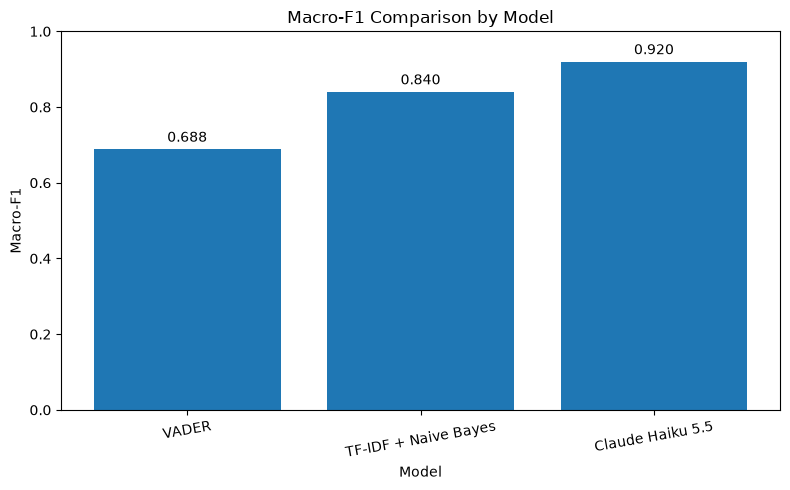

In [22]:
plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    comparison_table["model"],
    comparison_table["macro_f1"]
)

plt.title(
    "Macro-F1 Comparison by Model"
)

plt.xlabel("Model")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)

for bar, score in zip(
    bars,
    comparison_table["macro_f1"]
):
    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    "macro_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.2 Hard-case accuracy chart

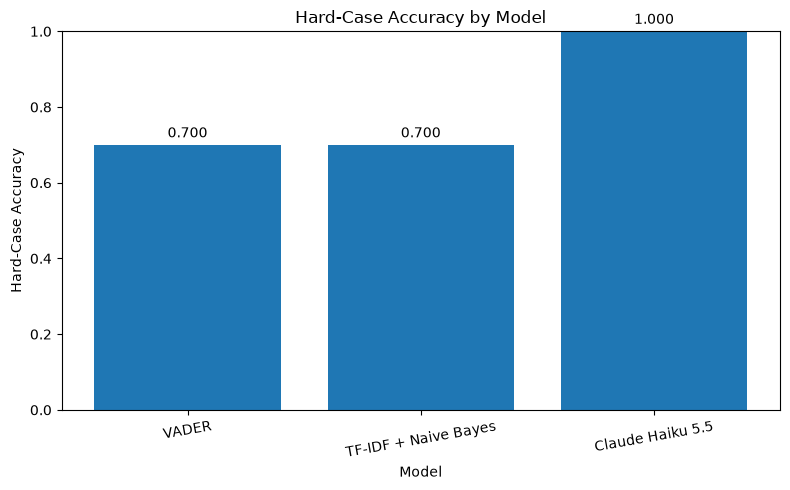

In [23]:
plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    comparison_table["model"],
    comparison_table[
        "hard_cases_accuracy"
    ]
)

plt.title(
    "Hard-Case Accuracy by Model"
)

plt.xlabel("Model")
plt.ylabel("Hard-Case Accuracy")
plt.ylim(0, 1)

for bar, score in zip(
    bars,
    comparison_table[
        "hard_cases_accuracy"
    ]
):
    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    "hard_case_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. Hard-case error analysis

### 10.1 Identify model correctness

In [24]:
hard_cases["vader_correct"] = (
    hard_cases["vader_prediction"]
    == hard_cases["label"]
)

hard_cases["nb_correct"] = (
    hard_cases["nb_prediction"]
    == hard_cases["label"]
)

hard_cases["claude_correct"] = (
    hard_cases["claude_prediction"]
    == hard_cases["label"]
)

hard_cases[
    [
        "case_id",
        "category",
        "label",
        "vader_prediction",
        "nb_prediction",
        "claude_prediction",
        "vader_correct",
        "nb_correct",
        "claude_correct"
    ]
]

,case_id,category,label,vader_prediction,nb_prediction,claude_prediction,vader_correct,nb_correct,claude_correct
0,1,contrast,positive,positive,positive,positive,True,True,True
1,2,negation,positive,positive,positive,positive,True,True,True
2,3,mixed,positive,positive,positive,positive,True,True,True
3,4,contrast,positive,positive,negative,positive,True,False,True
4,5,negation,positive,positive,negative,positive,True,False,True
5,6,mixed,positive,positive,positive,positive,True,True,True
6,7,implicit,positive,positive,positive,positive,True,True,True
7,8,idiomatic,positive,positive,positive,positive,True,True,True
8,9,implicit,positive,positive,positive,positive,True,True,True
9,10,mixed,positive,positive,positive,positive,True,True,True


### 10.2 Find model disagreements

In [25]:
disagreements = hard_cases[
    (
        hard_cases["vader_prediction"]
        != hard_cases["nb_prediction"]
    )
    |
    (
        hard_cases["vader_prediction"]
        != hard_cases["claude_prediction"]
    )
    |
    (
        hard_cases["nb_prediction"]
        != hard_cases["claude_prediction"]
    )
].copy()

print(
    "Hard cases with model disagreement:",
    len(disagreements)
)

disagreements[
    [
        "case_id",
        "text",
        "category",
        "label",
        "vader_prediction",
        "nb_prediction",
        "claude_prediction"
    ]
]

Hard cases with model disagreement: 13


,case_id,text,category,label,vader_prediction,nb_prediction,claude_prediction
3,4,"The beginning was slow, but the ending made th...",contrast,positive,positive,negative,positive
4,5,I would not say it was boring; it kept me inte...,negation,positive,positive,negative,positive
10,11,"The trailer made it look terrible, so I was su...",contrast,positive,positive,negative,positive
11,12,It was hardly a waste of time.,negation,positive,negative,negative,positive
15,16,What a brilliant idea: make a two-hour movie w...,sarcasm,negative,positive,negative,negative
19,20,The actors did their best with a script that s...,mixed,negative,positive,negative,negative
20,21,"If falling asleep was the goal, this film succ...",sarcasm,negative,positive,positive,negative
21,22,The movie is beautifully filmed and painfully ...,mixed,negative,negative,positive,negative
22,23,I cannot remember the last time a comedy made ...,negation,negative,positive,positive,negative
24,25,The only good part was when the credits finall...,sarcasm,negative,positive,negative,negative


### 10.3 Accuracy by hard-case category

In [26]:
category_analysis = (
    hard_cases
    .groupby("category")
    .agg(
        cases=("case_id", "count"),
        vader_accuracy=(
            "vader_correct",
            "mean"
        ),
        naive_bayes_accuracy=(
            "nb_correct",
            "mean"
        ),
        claude_accuracy=(
            "claude_correct",
            "mean"
        )
    )
    .reset_index()
)

category_analysis[
    [
        "vader_accuracy",
        "naive_bayes_accuracy",
        "claude_accuracy"
    ]
] = category_analysis[
    [
        "vader_accuracy",
        "naive_bayes_accuracy",
        "claude_accuracy"
    ]
].round(4)

category_analysis

,category,cases,vader_accuracy,naive_bayes_accuracy,claude_accuracy
0,contrast,6,0.8333,0.5000,1.0
1,idiomatic,1,1.0000,1.0000,1.0
2,implicit,5,0.8000,1.0000,1.0
3,intensification,1,1.0000,1.0000,1.0
4,mixed,7,0.8571,0.8571,1.0
5,negation,6,0.6667,0.5000,1.0
6,sarcasm,4,0.0000,0.5000,1.0


### 10.4 Saving it

In [27]:
category_analysis.to_csv(
    "hard_case_category_analysis.csv",
    index=False
)

disagreements.to_csv(
    "model_disagreements.csv",
    index=False
)

print(
    "Saved: hard_case_category_analysis.csv"
)

print(
    "Saved: model_disagreements.csv"
)

Saved: hard_case_category_analysis.csv
Saved: model_disagreements.csv


# 11. Create automatic findings for the report

### 11.1 Identify the strongest models

In [28]:
best_main_model = comparison_table.loc[
    comparison_table[
        "macro_f1"
    ].idxmax(),
    "model"
]

best_hard_model = comparison_table.loc[
    comparison_table[
        "hard_cases_accuracy"
    ].idxmax(),
    "model"
]

fastest_model = comparison_table.loc[
    comparison_table[
        "seconds_per_1000"
    ].idxmin(),
    "model"
]

lowest_cost = comparison_table[
    "cost_per_1000"
].min()

lowest_cost_models = comparison_table.loc[
    comparison_table[
        "cost_per_1000"
    ] == lowest_cost,
    "model"
].tolist()

print(
    "Best main-test Macro-F1:",
    best_main_model
)

print(
    "Best hard-case model:",
    best_hard_model
)

print(
    "Fastest model:",
    fastest_model
)

print(
    "Lowest-cost model(s):",
    lowest_cost_models
)

Best main-test Macro-F1: Claude Haiku 5.5
Best hard-case model: Claude Haiku 5.5
Fastest model: TF-IDF + Naive Bayes
Lowest-cost model(s): ['VADER', 'TF-IDF + Naive Bayes']


### 11.2 Summary

In [29]:
print("DAY 5 MODEL COMPARISON")
print("=" * 60)

print("\nMain comparison:")
display(display_table)

print(
    "\nBest main-test Macro-F1:",
    best_main_model
)

print(
    "Best hard-case accuracy:",
    best_hard_model
)

print(
    "Fastest model:",
    fastest_model
)

print(
    "Lowest-cost model(s):",
    lowest_cost_models
)

print(
    "\nHard-case disagreements:",
    len(disagreements)
)

print("\nSaved outputs:")
print("- metrics.csv")
print("- hard_cases.csv")
print("- hard_case_results.csv")
print("- hard_cases_claude_cache.jsonl")
print("- hard_case_category_analysis.csv")
print("- model_disagreements.csv")
print("- macro_f1_comparison.png")
print("- hard_case_accuracy.png")

print("\nDAY 5 COMPLETE")

DAY 5 MODEL COMPARISON

Main comparison:


,Model,Accuracy (%),Macro-F1 (%),Hard-Cases Accuracy (%),"Seconds / 1,000 Predictions","Cost / 1,000 Predictions ($)"
0,VADER,69.67,68.84,70.0,2.4867,0.000000
1,TF-IDF + Naive Bayes,84.00,84.00,70.0,0.0089,0.000000
2,Claude Haiku 5.5,92.00,91.96,100.0,860.9965,0.052979



Best main-test Macro-F1: Claude Haiku 5.5
Best hard-case accuracy: Claude Haiku 5.5
Fastest model: TF-IDF + Naive Bayes
Lowest-cost model(s): ['VADER', 'TF-IDF + Naive Bayes']

Hard-case disagreements: 13

Saved outputs:
- metrics.csv
- hard_cases.csv
- hard_case_results.csv
- hard_cases_claude_cache.jsonl
- hard_case_category_analysis.csv
- model_disagreements.csv
- macro_f1_comparison.png
- hard_case_accuracy.png

DAY 5 COMPLETE
